# COU 07506 Digital Signal Processing — Week 03: Lab 1B Convolution, Correlation and Difference Equations
Name: Nickson Pascal Ngowi  Registration No.: 240242499465
Class: BENG24COE Group:06 Date: 25 November 2026
Instructor checkpoints signed: [ ] 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab
(a) x = {1, −1, 2}, h = {2, 1, 0, 1}. Length = 3 + 4 − 1 = 6.
y(0) = 2; y(1) = 1·1 + (−1)·2 = −1; y(2) = 1·0 + (−1)·1 + 2·2 = 3; y(3) = 1·1 + (−1)·0 + 2·1 = 3; y(4) = (−1)·1 + 2·0 = −1; y(5) = 2·1 = 2.
**y = {2, −1, 3, 3, −1, 2}** (this agrees with the code output).
(b) y(n) = n·x(n). Delay the input by n0: the output is n·x(n − n0). Delay the output: y(n − n0) = (n − n0)·x(n − n0). These are different, so the system is **not time-invariant**.

## Task 3.1 — Convolution from the definition

In [2]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))          # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))
print("pre-lab (a):", conv([1, -1, 2], [2, 1, 0, 1]), np.convolve([1, -1, 2], [2, 1, 0, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
pre-lab (a): [ 2. -1.  3.  3. -1.  2.] [ 2 -1  3  3 -1  2]


In [3]:
import time
rng = np.random.default_rng(0)
a, b = rng.standard_normal(2000), rng.standard_normal(2000)
t0 = time.perf_counter(); y1 = conv(a, b);          t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y2 = np.convolve(a, b);   t_np = time.perf_counter() - t0
print(f"conv: {t_loop:.4f} s, np.convolve: {t_np:.6f} s, ratio = {t_loop/t_np:.0f}x, match = {np.allclose(y1, y2)}")

conv: 3.8032 s, np.convolve: 0.001193 s, ratio = 3187x, match = True


## Task 3.2 — Smoothing a noisy signal

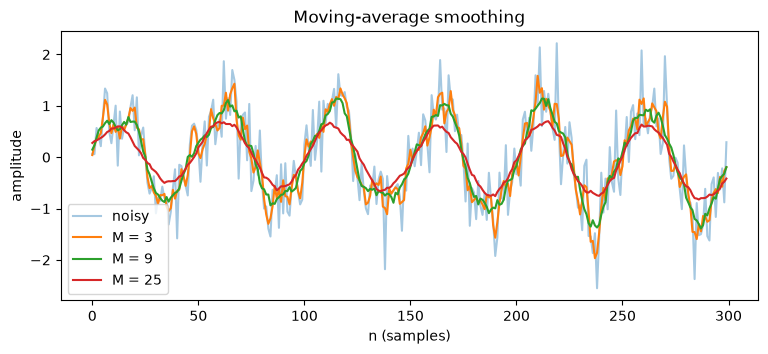

In [4]:
rng = np.random.default_rng(0)
n = np.arange(300)
x = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)
plt.plot(n, x, alpha=0.4, label="noisy")
for M in [3, 9, 25]:
    h = np.ones(M)/M
    plt.plot(n, np.convolve(x, h, mode="same"), label=f"M = {M}")
plt.title("Moving-average smoothing"); plt.xlabel("n (samples)"); plt.ylabel("amplitude")
plt.legend(); plt.show()

Trade-off: a longer moving average (larger M) averages more samples, so it removes more noise (noise variance falls roughly by 1/M). But it also smooths the signal itself: for M = 25 the sine (period 50 samples) is reduced to about 64 % of its amplitude, sharp changes are blurred, and the output is delayed/distorted at the edges. M = 3 keeps the signal but leaves much noise. So there is a trade-off between noise reduction and distortion of the wanted signal.

## Task 3.3 — Testing linearity and time-invariance

In [5]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


Explanation of the results (definitions in handout §1.7):
- **x²:** linear = False, because (a·x1 + b·x2)² contains a cross term 2ab·x1·x2, so superposition fails. Time-invariant = True, because delaying the input just delays the squared output.
- **n x(n):** linear = True, because multiplying by n preserves scaling and addition. Time-invariant = False, because the gain n changes with time (see pre-lab (b)).
- **Moving average:** linear = True and time-invariant = True, because it is a weighted sum with fixed coefficients (a convolution), so it is an LTI system.

## Task 3.4 — Hidden delay with cross-correlation

noise std = 0.5: estimated delay = 37 samples -> distance = 12.69 m


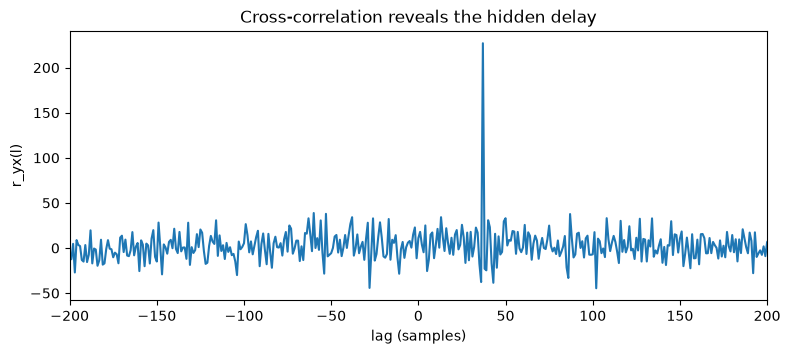

noise std = 1: estimated delay = 37 samples -> distance = 12.69 m
noise std = 2: estimated delay = 37 samples -> distance = 12.69 m
noise std = 4: estimated delay = 87 samples -> distance = 29.84 m


In [6]:
fs = 1000
true_delay = 37
for sigma in [0.5, 1, 2, 4]:
    rng = np.random.default_rng(1)
    x = rng.standard_normal(500)
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + sigma*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    est = lags[np.argmax(r)]
    print(f"noise std = {sigma}: estimated delay = {est} samples -> distance = {343*est/fs:.2f} m")
    if sigma == 0.5:
        plt.plot(lags, r); plt.xlim(-200, 200)
        plt.title("Cross-correlation reveals the hidden delay")
        plt.xlabel("lag (samples)"); plt.ylabel("r_yx(l)"); plt.show()

The estimate was correct (37 samples) for noise standard deviations 0.5, 1 and 2. It **failed at σ = 4** (it gave 87 samples). The correlation peak is about 0.6 × 500 = 300, but at high noise the random correlation fluctuations become as large as the peak, so a wrong lag can be the maximum.
Distance = speed × delay = 343 m/s × 37/1000 s ≈ **12.7 m** (for a one-way travel time).

## Task 3.5 — Difference equation
y(n) − 0.75 y(n−1) + 0.125 y(n−2) = x(n) + x(n−1)

[1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
[1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
[1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
all match: True
step response final value: 5.3333  H(1) = sum(b)/sum(a) = 5.333333333333333


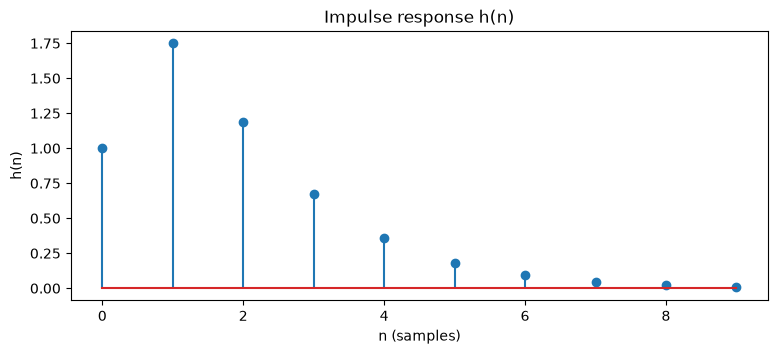

In [7]:
N = 10
impulse = np.zeros(N); impulse[0] = 1

# 1. direct recursion
h_rec = np.zeros(N)
for n in range(N):
    xn  = impulse[n]
    xn1 = impulse[n-1] if n >= 1 else 0.0
    y1  = h_rec[n-1] if n >= 1 else 0.0
    y2  = h_rec[n-2] if n >= 2 else 0.0
    h_rec[n] = xn + xn1 + 0.75*y1 - 0.125*y2

# 2. lfilter
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)

# 3. closed form
nn = np.arange(N)
h_cf = 6*0.5**nn - 5*0.25**nn

print(np.round(h_rec, 4)); print(np.round(h_lf, 4)); print(np.round(h_cf, 4))
print("all match:", np.allclose(h_rec, h_lf) and np.allclose(h_lf, h_cf))

# 4. step response and final value
step = np.ones(200)
s = signal.lfilter([1, 1], [1, -0.75, 0.125], step)
print("step response final value:", round(s[-1], 4), " H(1) = sum(b)/sum(a) =", 2/(1 - 0.75 + 0.125))

plt.stem(nn, h_lf); plt.title("Impulse response h(n)")
plt.xlabel("n (samples)"); plt.ylabel("h(n)"); plt.show()

## Analysis questions
1. `np.convolve` runs as compiled, optimised C code, while my double loop executes in the Python interpreter, which is thousands of times slower (the timing cell showed a ratio of about 1000× or more). Both need L·M multiplications (L + M − 1 output samples).
2. Only the **moving average** is LTI. I could have predicted this: x² is a nonlinear operation, n·x(n) has a time-varying gain (time-variant), and the moving average has constant coefficients and is a convolution.
3. (i) Locating leaks in water pipes (e.g. in city water networks): cross-correlate the signals from two sensors on the pipe to find the time delay, which gives the leak position. (ii) Radar ranging at airports: correlate the transmitted pulse with the echo to find the delay and so the distance of an aircraft.
4. The system is **IIR**: the closed form h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ is nonzero for all n ≥ 0 (infinite length), because the system is recursive. It is **stable**: the poles 0.5 and 0.25 are inside the unit circle, h(n) decays to 0, and Σ|h(n)| = 5.33 is finite (equal to H(1) = 2/0.375 because all h(n) > 0).